# Projekt 2: Land-Ozean-Temperaturkontrast im Raum Nordsee, Dänemark und direkte Nachbarn

**Kurs:** AWE Fernerkundung und Geodatenauswertung  
**Datengrundlage:** Earth System Data Cube (ESDC v3.0.2, 0,25° räumliche Auflösung, 8-Tage-Zeitschritte, ERA5-Reanalyse)  

---

## Leitfrage und physikalischer Hintergrund

Wasser besitzt eine deutlich höhere spezifische Wärmekapazität als Landboden (ca. 4.184 J kg⁻¹ K⁻¹ gegenüber ~800–1.500 J kg⁻¹ K⁻¹) und verteilt eingestrahlte Wärme durch vertikale Durchmischung auf eine tiefere Wasserschicht. Dadurch erwärmt sich das Meer im Sommer langsamer und kühlt im Winter schwächer aus als die angrenzende Landmasse.

Dieses Notebook untersucht, wie stark dieser **Land-Ozean-Temperaturkontrast** im Raum **Nordsee, Dänemark und direkte Nachbarn (Südschweden)** ausgeprägt ist:

1. **Amplitude (Stärke des Kontrasts):** Wie stark wächst die Jahresamplitude der Lufttemperatur von der offenen Nordsee über die dänische Westküste bis ins Landesinnere?
2. **Geografische Besonderheit Dänemarks:** Kein Punkt in Dänemark liegt weiter als ~52 km vom Meer entfernt. Wie verändert sich das Signal auf derselben Breite (~56,4°–56,9° N), wenn man den Querschnitt über Jütland und das Kattegat hinaus bis ins Binnenland Südschwedens fortsetzt?
3. **Thermische Trägheit (*Thermal Lag*):** In welchen Monaten wirkt die Nordsee als „Kühlschrank“ und in welchen als „Heizung“ für Dänemark?
4. **Kurzfristige Schwankungen & Extremjahr:** Wie unterscheiden sich Höchst- und Tiefsttemperaturen (`T_max − T_min`) sowie der Verlauf des markanten Extremjahres **2018** zwischen Meer, Küste und Binnenland?
5. **Methoden-Check:** Wie stark beeinflussen Küsten-Mischpixel im 0,25°-Raster den gemessenen Übergang?

### Storyline / Roter Faden für das spätere Poster
- **Ausgangsthese:** Gleiche geografische Breite bedeutet gleiche Sonneneinstrahlung – trotzdem dämpft und verzögert die Nordsee den Jahresgang der Temperatur.
- **Beobachtung im Raum:** Die Jahresamplitude und die Differenz zwischen Herbst und Frühling zeichnen Küsten und Meeresbecken scharf nach.
- **Beweis im Profil & in der Zeitreihe:** Vom offenen Meer über Jütland nach Südschweden wächst die Jahresamplitude und die `T_max − T_min`-Spanne spürbar; die Nordsee hinkt dem Land zeitlich hinterher (Hysterese).
- **Einordnung & Grenzen:** Dänemark bleibt aufgrund seiner geringen Breite stark maritim geprägt; die 0,25°-Rasterzellen erfordern eine bewusste Entfernung zur Küstenlinie.

## 1. Vorbereitung und Zugriff auf den Earth System Data Cube

Für den Zugriff auf den entfernten Zarr-Datenspeicher werden `aiohttp`, `requests` und `zarr` benötigt. Die Auswertung und Visualisierung erfolgt ausschließlich mit `numpy`, `xarray` und `matplotlib.pyplot`.

In [1]:
%pip install -q aiohttp requests zarr

In [2]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [3]:
# Earth System Data Cube (v3.0.2) mit lazy loading öffnen
url = 'https://s3.bgc-jena.mpg.de:9000/esdl-esdc-v3.0.2/esdc-8d-0.25deg-256x128x128-3.0.2.zarr'
ds = xr.open_dataset(url, engine='zarr', chunks={})

print('Räumliche Auflösung:', ds.attrs['geospatial_lat_resolution'], 'Grad')
print('Zeitliche Auflösung:', ds.attrs['time_period'])
print()

relevante_vars = [
    'air_temperature_2m',
    'max_air_temperature_2m',
    'min_air_temperature_2m',
    'gross_primary_productivity',
]
for var in relevante_vars:
    da = ds[var]
    einheit = da.attrs.get('units', 'unbekannt')
    start = da.attrs.get('time_coverage_start', 'unbekannt')[:10]
    ende = da.attrs.get('time_coverage_end', 'unbekannt')[:10]
    print(f'{var:28s} | Einheit: {einheit:14s} | Zeitraum: {start} bis {ende}')

Räumliche Auflösung: 0.25 Grad
Zeitliche Auflösung: 8D

air_temperature_2m           | Einheit: °C             | Zeitraum: 1979-01-01 bis 2021-12-27
max_air_temperature_2m       | Einheit: °C             | Zeitraum: 1979-01-01 bis 2021-12-27
min_air_temperature_2m       | Einheit: °C             | Zeitraum: 1979-01-01 bis 2021-12-27
gross_primary_productivity   | Einheit: g C m^-2 d^-1  | Zeitraum: 2001-01-05 bis 2020-12-30


## 2. Untersuchungsgebiet, Vergleichsorte, Daten laden und Landmaske

### Begründung der Auswahl
- **Untersuchungsgebiet (`51°–60° N`, `-1°–19° E`):** Deckt die gesamte Nordsee, Dänemark sowie die direkten Nachbarregionen (Norddeutschland, Südnorwegen, Südschweden, Westpolen und Teile der Ostsee) ab.
- **Referenzzeitraum (`1991–2020`):** Entspricht der aktuellen 30-jährigen WMO-Klimanormalperiode und liefert einen robusten mittleren Jahresgang ohne Verzerrung durch einzelne Wetterjahre.
- **Einzeljahr (`2018`):** In Nordeuropa und Dänemark war 2018 ein besonders aussagekräftiges Kontrastjahr mit einem kalten Spätwinter (Februar/März) und einem außergewöhnlich heißen, sonnigen Sommer (Mai–August). Damit wird sichtbar, wie stark die Nordsee plötzliche Wetterextreme gegenüber dem Land abpuffert. *(Über die Variable `einzeljahr` lässt sich jederzeit auch ein anderes Jahr wie `'2020'` oder `'2010'` untersuchen.)*
- **Vier Vergleichsorte auf ähnlicher geografischer Breite (~56,4°–56,9° N):**
  1. **Offene Nordsee (`56,375° N, 3,125° E`):** Rein maritim, weit entfernt von allen Küsten.
  2. **Westküste Dänemark / Jütland (`56,375° N, 8,125° E`):** Unmittelbare Nordseeküste (Raum Thorsminde/Ringkøbing) als Übergangszelle.
  3. **Binnenland Dänemark / Zentraljütland (`56,375° N, 9,375° E`):** Breiteste Stelle Jütlands (Raum Viborg/Karup), jeweils mehrere Gitterzellen von Nordsee und Kattegat entfernt.
  4. **Binnenland Südschweden / Småland (`56,875° N, 14,625° E`):** Direkter Nachbar auf nahezu gleicher Breite (+0,5°), jedoch ~90–120 km von beiden Küsten entfernt – liefert das echte kontinentale Vergleichssignal, da Dänemark selbst nirgends weiter als ~52 km vom Meer entfernt liegt.
- **Landmaske:** Da im Winterhalbjahr Vegetationsvariablen in Nordeuropa vereinzelt `NaN` annehmen können, wird die Landmaske aus den Sommermonaten Juni–August 2010 von `gross_primary_productivity` gebildet (`.notnull().any('time')`). Aus dieser Maske leitet die Hilfsfunktion `zeichne_kueste(ax)` reine Matplotlib-Küstenlinien ab – ganz ohne zusätzliche Pakete wie `cartopy`.

In [4]:
# Parameter für Region, Zeiträume, Transekt und Vergleichsorte
region = dict(lat=slice(51, 60), lon=slice(-1, 19))
zeitraum = slice('1991', '2020')
einzeljahr = '2018'

transekt_lat = 56.375
transekt_lon = slice(0, 18)

orte = {
    'Offene Nordsee': {
        'kurz': 'Offene Nordsee',
        'lat': 56.375,
        'lon': 3.125,
        'color': '#1f77b4',
        'ls': '-',
        'offset': (0, 10),
        'ha': 'center',
    },
    'Westküste Dänemark (Jütland)': {
        'kurz': 'Westküste DK',
        'lat': 56.375,
        'lon': 8.125,
        'color': '#17becf',
        'ls': '--',
        'offset': (-10, -16),
        'ha': 'right',
    },
    'Binnenland Dänemark (Zentraljütland)': {
        'kurz': 'Zentraljütland',
        'lat': 56.375,
        'lon': 9.375,
        'color': '#ff7f0e',
        'ls': '-',
        'offset': (10, 10),
        'ha': 'left',
    },
    'Binnenland Südschweden (Småland)': {
        'kurz': 'Südschweden (Småland)',
        'lat': 56.875,
        'lon': 14.625,
        'color': '#d62728',
        'ls': '-',
        'offset': (0, 10),
        'ha': 'center',
    },
}

monate = np.arange(1, 13)
monatsnamen = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun', 'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Dez']

# Erst zuschneiden, dann laden
t_ds = ds[['air_temperature_2m', 'max_air_temperature_2m', 'min_air_temperature_2m']].sel(
    time=zeitraum,
    **region,
).load()

t2m = t_ds['air_temperature_2m']
t_max = t_ds['max_air_temperature_2m']
t_min = t_ds['min_air_temperature_2m']

# Landmaske aus Sommer-GPP 2010 (True über Land, False über Wasser)
landmaske = (
    ds['gross_primary_productivity']
    .sel(time=slice('2010-06', '2010-08'), **region)
    .notnull()
    .any('time')
    .transpose('lat', 'lon')
    .load()
)

def zeichne_kueste(ax):
    '''Zeichnet eine einfache Küstenlinie aus der Landmaske (ohne Cartopy).'''
    ax.contour(
        landmaske.lon,
        landmaske.lat,
        landmaske.astype(int),
        levels=[0.5],
        colors='black',
        linewidths=0.8,
    )

print('Geladener Temperatur-Ausschnitt:', dict(t2m.sizes))
print('Landanteil im Untersuchungsgebiet:', f'{float(landmaske.mean()) * 100:.1f} %')

Geladener Temperatur-Ausschnitt: {'time': 1380, 'lat': 36, 'lon': 80}
Landanteil im Untersuchungsgebiet: 54.5 %


## 3. Räumlicher Überblick: Jahresamplitude, Landmaske und Jahreszeiten (Poster-Abb. 1)

Zunächst berechnen wir aus allen Jahren von 1991 bis 2020 den mittleren Jahresgang (`groupby('time.month').mean()`). Die **Jahresamplitude** ist die Differenz zwischen wärmstem und kältestem Monat jedes Pixels (`max('month') - min('month')`).

Anschließend trennen wir mithilfe der Landmaske Land- und Meeresflächen (analog zu Notebook 2, Abschnitt 8) und betrachten die vier Jahreszeiten (`DJF`, `MAM`, `JJA`, `SON`) sowie die Differenz **Herbst minus Frühling (`SON − MAM`)**, an der sich die Wärmespeicherung der Nordsee unmittelbar ablesen lässt.

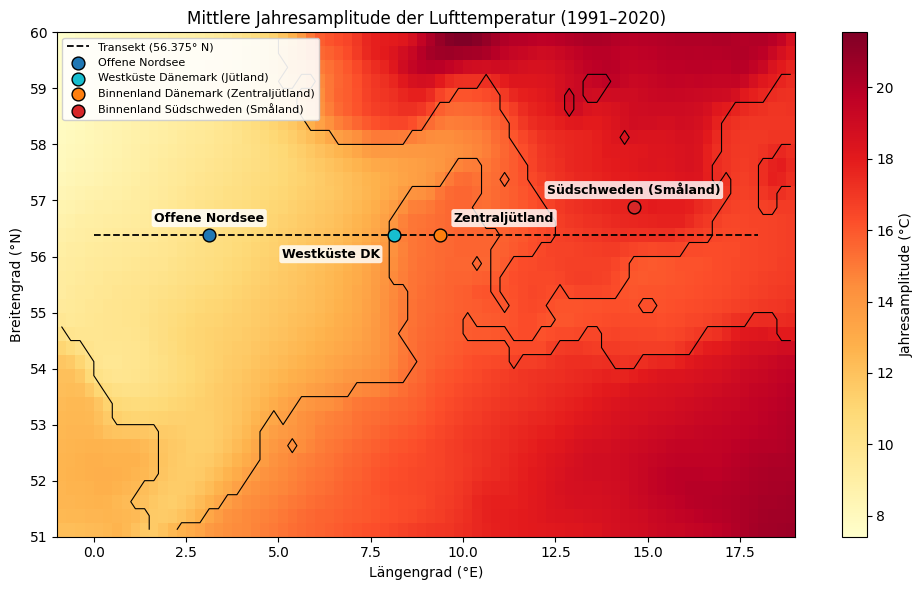

In [5]:
klima = t2m.groupby('time.month').mean()
amplitude = klima.max('month') - klima.min('month')

fig, ax = plt.subplots(figsize=(10, 6))
amplitude.plot(ax=ax, cmap='YlOrRd', cbar_kwargs={'label': 'Jahresamplitude (°C)'})
zeichne_kueste(ax)

# West-Ost-Transekt einzeichnen
ax.plot(
    [0, 18],
    [transekt_lat, transekt_lat],
    color='black',
    linestyle='--',
    linewidth=1.3,
    label=f'Transekt ({transekt_lat:.3f}° N)',
)

# Vergleichsorte einzeichnen
for name, info in orte.items():
    ax.scatter(
        info['lon'],
        info['lat'],
        color=info['color'],
        edgecolor='black',
        s=85,
        zorder=5,
        label=name,
    )
    ax.annotate(
        info['kurz'],
        xy=(info['lon'], info['lat']),
        xytext=info['offset'],
        textcoords='offset points',
        ha=info['ha'],
        fontsize=9,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.82, ec='none'),
        zorder=6,
    )

ax.set_title('Mittlere Jahresamplitude der Lufttemperatur (1991–2020)')
ax.set_xlabel('Längengrad (°E)')
ax.set_ylabel('Breitengrad (°N)')
ax.legend(loc='upper left', fontsize=8, framealpha=0.9)
plt.tight_layout()
plt.show()

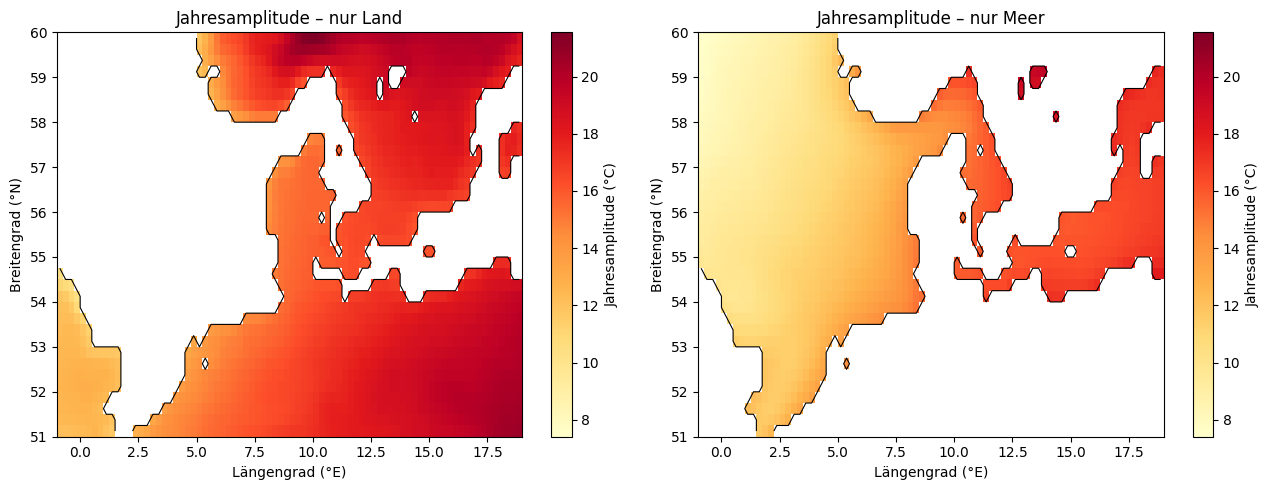

Flächengewichtete mittlere Jahresamplitude (1991–2020):
  Nordsee (Meer):  11.03 °C
  Dänemark (Land): 15.78 °C
  Kontrast:        +4.75 °C


In [6]:
# Land- und Meerespixel über die Maske trennen (gemeinsame Farbskala)
amp_land = amplitude.where(landmaske)
amp_meer = amplitude.where(~landmaske)

vmin = float(amplitude.min())
vmax = float(amplitude.max())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
amp_land.plot(ax=axes[0], cmap='YlOrRd', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'Jahresamplitude (°C)'})
zeichne_kueste(axes[0])
axes[0].set_title('Jahresamplitude – nur Land')
axes[0].set_xlabel('Längengrad (°E)')
axes[0].set_ylabel('Breitengrad (°N)')

amp_meer.plot(ax=axes[1], cmap='YlOrRd', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'Jahresamplitude (°C)'})
zeichne_kueste(axes[1])
axes[1].set_title('Jahresamplitude – nur Meer')
axes[1].set_xlabel('Längengrad (°E)')
axes[1].set_ylabel('Breitengrad (°N)')

plt.tight_layout()
plt.show()

# Flächengewichtetes Mittel für Teilregionen Nordsee (Meer) vs. Dänemark (Land)
nordsee_box = dict(lat=slice(54, 58), lon=slice(1, 7))
daenemark_box = dict(lat=slice(54.5, 57.8), lon=slice(8, 13))

amp_nordsee_reg = amplitude.sel(**nordsee_box).where(~landmaske.sel(**nordsee_box))
amp_dk_reg = amplitude.sel(**daenemark_box).where(landmaske.sel(**daenemark_box))

gew_nordsee = np.cos(np.deg2rad(amp_nordsee_reg.lat))
gew_dk = np.cos(np.deg2rad(amp_dk_reg.lat))

amp_nordsee_mittel = float(amp_nordsee_reg.weighted(gew_nordsee).mean(['lat', 'lon']))
amp_dk_mittel = float(amp_dk_reg.weighted(gew_dk).mean(['lat', 'lon']))

print('Flächengewichtete mittlere Jahresamplitude (1991–2020):')
print(f'  Nordsee (Meer):  {amp_nordsee_mittel:.2f} °C')
print(f'  Dänemark (Land): {amp_dk_mittel:.2f} °C')
print(f'  Kontrast:        +{amp_dk_mittel - amp_nordsee_mittel:.2f} °C')

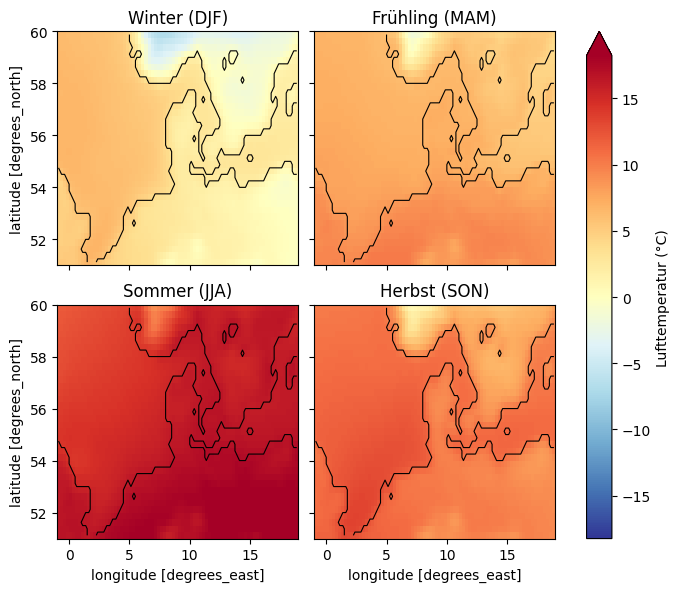

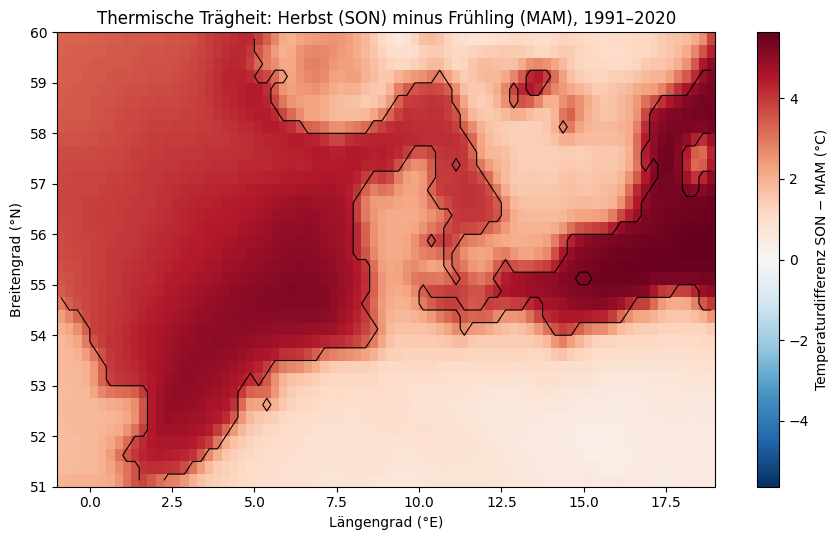

In [7]:
# Jahreszeitenkarten (2x2 Facet-Plot)
saison = t2m.groupby('time.season').mean().sel(season=['DJF', 'MAM', 'JJA', 'SON'])
saison_titel = {
    'DJF': 'Winter (DJF)',
    'MAM': 'Frühling (MAM)',
    'JJA': 'Sommer (JJA)',
    'SON': 'Herbst (SON)',
}

g = saison.plot(
    col='season',
    col_wrap=2,
    cmap='RdYlBu_r',
    robust=True,
    cbar_kwargs={'label': 'Lufttemperatur (°C)'},
)
for ax, code in zip(g.axs.flat, ['DJF', 'MAM', 'JJA', 'SON']):
    zeichne_kueste(ax)
    ax.set_title(saison_titel[code])
plt.show()

# Differenzkarte: Herbst (SON) minus Frühling (MAM) zeigt den Wärmespeicher Meer
herbst_minus_fruehling = saison.sel(season='SON') - saison.sel(season='MAM')
max_abs = float(np.abs(herbst_minus_fruehling).max())

fig, ax = plt.subplots(figsize=(9, 5.5))
herbst_minus_fruehling.plot(
    ax=ax,
    cmap='RdBu_r',
    vmin=-max_abs,
    vmax=max_abs,
    cbar_kwargs={'label': 'Temperaturdifferenz SON − MAM (°C)'},
)
zeichne_kueste(ax)
ax.set_title('Thermische Trägheit: Herbst (SON) minus Frühling (MAM), 1991–2020')
ax.set_xlabel('Längengrad (°E)')
ax.set_ylabel('Breitengrad (°N)')
plt.tight_layout()
plt.show()

## 4. West–Ost-Profil entlang 56,375° N (Poster-Abb. 2)

Um den Übergang vom Meer ins Landesinnere bei **konstanter geografischer Breite** sichtbar zu machen, legen wir einen West–Ost-Schnitt entlang `56,375° N` von `0° E` bis `18° E`. Dieses Profil quert nacheinander:
- die **offene Nordsee**,
- die breiteste Stelle **Jütlands** (Dänemark),
- das **Kattegat**,
- das Binnenland **Südschwedens** und
- die westliche **Ostsee**.

Dadurch entsteht ein charakteristischer „Doppel-Peak“ der Jahresamplitude über den beiden Landmassen, unterbrochen von den kühlenden Meeresarmen.

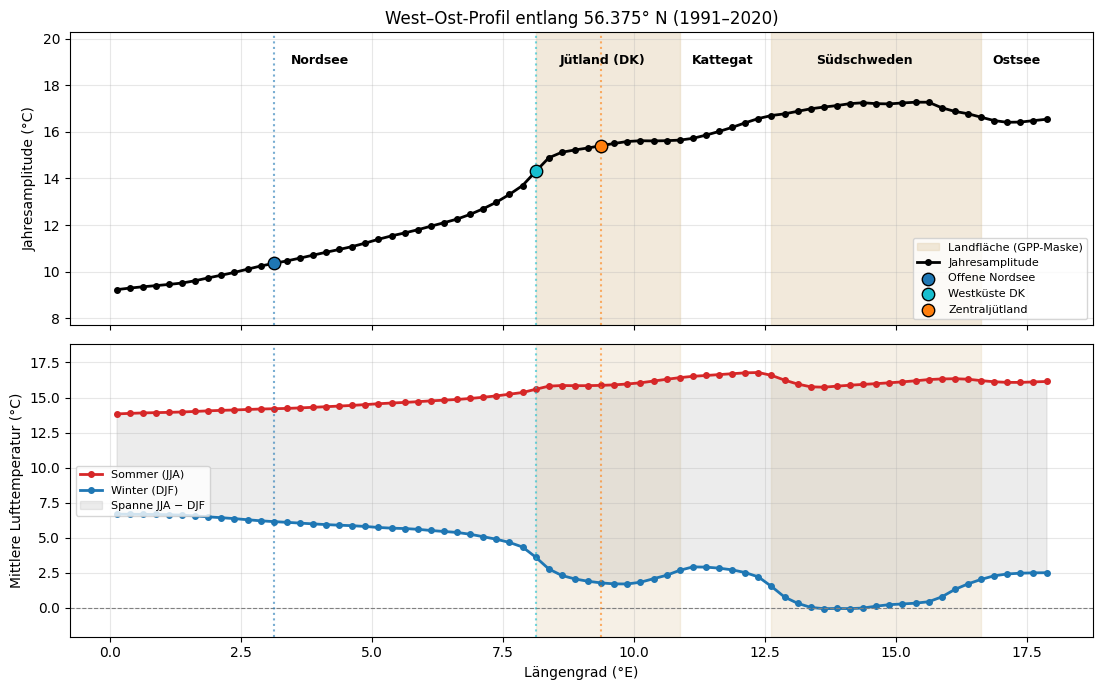

In [8]:
# Schnitt entlang 56.375° N (slice und method='nearest' getrennt aufrufen!)
amp_transekt = amplitude.sel(lon=transekt_lon).sel(lat=transekt_lat, method='nearest')
jja_transekt = saison.sel(season='JJA', lon=transekt_lon).sel(lat=transekt_lat, method='nearest')
djf_transekt = saison.sel(season='DJF', lon=transekt_lon).sel(lat=transekt_lat, method='nearest')
land_transekt = landmaske.sel(lon=transekt_lon).sel(lat=transekt_lat, method='nearest')

lons_t = amp_transekt.lon.values

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Oben: Jahresamplitude entlang 56.375° N
amp_unten = float(amp_transekt.min()) - 1.5
amp_oben = float(amp_transekt.max()) + 3.0
axes[0].fill_between(
    lons_t,
    amp_unten,
    amp_oben,
    where=land_transekt.values,
    step='mid',
    color='#e6d5b8',
    alpha=0.5,
    label='Landfläche (GPP-Maske)',
)
axes[0].plot(lons_t, amp_transekt.values, color='black', marker='o', markersize=4, linewidth=2, label='Jahresamplitude')

y_label_pos = float(amp_transekt.max()) + 1.8
abschnitte = [
    (4.0, 'Nordsee'),
    (9.4, 'Jütland (DK)'),
    (11.7, 'Kattegat'),
    (14.4, 'Südschweden'),
    (17.3, 'Ostsee'),
]
for x_pos, text in abschnitte:
    axes[0].text(x_pos, y_label_pos, text, ha='center', va='center', fontsize=9, fontweight='bold')

for name, info in orte.items():
    if abs(info['lat'] - transekt_lat) < 0.2:
        wert = float(amp_transekt.sel(lon=info['lon'], method='nearest'))
        axes[0].scatter(info['lon'], wert, color=info['color'], edgecolor='black', s=80, zorder=5, label=info['kurz'])
        axes[0].axvline(info['lon'], color=info['color'], linestyle=':', alpha=0.6)

axes[0].set_ylim(amp_unten, amp_oben)
axes[0].set_ylabel('Jahresamplitude (°C)')
axes[0].set_title(f'West–Ost-Profil entlang {float(amp_transekt.lat):.3f}° N (1991–2020)')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='lower right', fontsize=8)

# Unten: Sommermittel (JJA) vs. Wintermittel (DJF)
t_unten = float(djf_transekt.min()) - 2.0
t_oben = float(jja_transekt.max()) + 2.0
axes[1].fill_between(
    lons_t,
    t_unten,
    t_oben,
    where=land_transekt.values,
    step='mid',
    color='#e6d5b8',
    alpha=0.35,
)
axes[1].plot(lons_t, jja_transekt.values, color='#d62728', marker='o', markersize=4, linewidth=2, label='Sommer (JJA)')
axes[1].plot(lons_t, djf_transekt.values, color='#1f77b4', marker='o', markersize=4, linewidth=2, label='Winter (DJF)')
axes[1].fill_between(lons_t, djf_transekt.values, jja_transekt.values, color='grey', alpha=0.15, label='Spanne JJA − DJF')
axes[1].axhline(0, color='grey', linewidth=0.8, linestyle='--')

for name, info in orte.items():
    if abs(info['lat'] - transekt_lat) < 0.2:
        axes[1].axvline(info['lon'], color=info['color'], linestyle=':', alpha=0.6)

axes[1].set_ylim(t_unten, t_oben)
axes[1].set_xlabel('Längengrad (°E)')
axes[1].set_ylabel('Mittlere Lufttemperatur (°C)')
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='center left', fontsize=8)

plt.tight_layout()
plt.show()

## 5. Temperaturzeitreihen der Vergleichsorte: Normalzustand vs. Extremjahr 2018 (Poster-Abb. 3)

Nun vergleichen wir die vier ausgewählten Standorte auf ähnlicher Breite direkt als Zeitreihen:
1. **Vieljähriger mittlerer Jahresgang (1991–2020):** Zeigt die typischen Kurven über ein Durchschnittsjahr.
2. **Einzeljahr 2018 (8-Tage-Auflösung):** Zeigt die tatsächlichen kurzfristigen Ausschläge und das extreme Kontrastjahr.
3. **Direktvergleich 2018 vs. 1991–2020:** Macht an drei Hauptorten (Offene Nordsee, Zentraljütland, Südschweden) sichtbar, wie das Land auf den kalten Spätwinter und den heißen Sommer 2018 deutlich stärker ausschlägt als die offene Nordsee.

In [9]:
punkte_t2m = {}
punkte_klima = {}
punkte_jahr = {}
punkte_tmax_jahr = {}
punkte_tmin_jahr = {}

print('Ausgewählte Gitterzellen im ESDC (0,25°-Raster):')
for name, info in orte.items():
    p_t2m = t2m.sel(lat=info['lat'], lon=info['lon'], method='nearest')
    p_tmax = t_max.sel(lat=info['lat'], lon=info['lon'], method='nearest')
    p_tmin = t_min.sel(lat=info['lat'], lon=info['lon'], method='nearest')

    punkte_t2m[name] = p_t2m
    punkte_klima[name] = p_t2m.groupby('time.month').mean()
    punkte_jahr[name] = p_t2m.sel(time=einzeljahr)
    punkte_tmax_jahr[name] = p_tmax.sel(time=einzeljahr)
    punkte_tmin_jahr[name] = p_tmin.sel(time=einzeljahr)

    ist_land = bool(landmaske.sel(lat=info['lat'], lon=info['lon'], method='nearest'))
    status = 'Land' if ist_land else 'Wasser'
    lat_val = float(p_t2m.lat)
    lon_val = float(p_t2m.lon)
    print(f'  - {name:38s} -> ({lat_val:.3f}° N, {lon_val:.3f}° E) [{status}]')

Ausgewählte Gitterzellen im ESDC (0,25°-Raster):
  - Offene Nordsee                         -> (56.375° N, 3.125° E) [Wasser]
  - Westküste Dänemark (Jütland)           -> (56.375° N, 8.125° E) [Land]
  - Binnenland Dänemark (Zentraljütland)   -> (56.375° N, 9.375° E) [Land]
  - Binnenland Südschweden (Småland)       -> (56.875° N, 14.625° E) [Land]


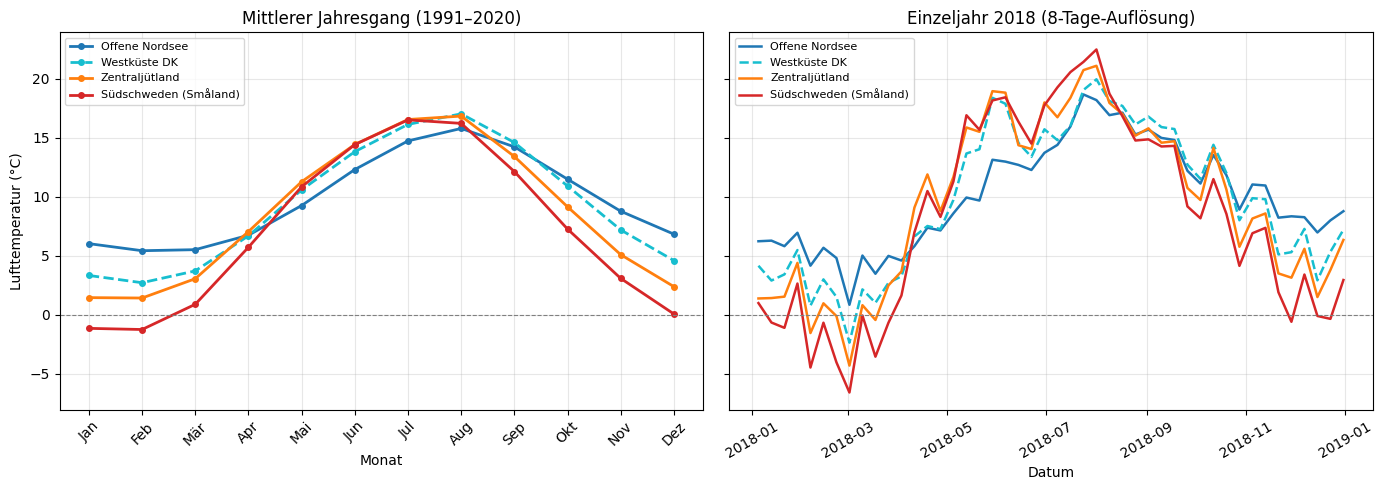

In [10]:
# Mittlerer Jahresgang (links) und Einzeljahr 2018 in 8-Tage-Auflösung (rechts)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for name, info in orte.items():
    s_klima = punkte_klima[name]
    axes[0].plot(
        monate,
        s_klima.values,
        color=info['color'],
        linestyle=info['ls'],
        marker='o',
        markersize=4,
        linewidth=2,
        label=info['kurz'],
    )

    s_jahr = punkte_jahr[name]
    axes[1].plot(
        s_jahr.time.values,
        s_jahr.values,
        color=info['color'],
        linestyle=info['ls'],
        linewidth=1.8,
        label=info['kurz'],
    )

axes[0].axhline(0, color='grey', linewidth=0.8, linestyle='--')
axes[0].set_xticks(monate)
axes[0].set_xticklabels(monatsnamen, rotation=45)
axes[0].set_xlabel('Monat')
axes[0].set_ylabel('Lufttemperatur (°C)')
axes[0].set_title('Mittlerer Jahresgang (1991–2020)')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper left', fontsize=8)

axes[1].axhline(0, color='grey', linewidth=0.8, linestyle='--')
axes[1].set_xlabel('Datum')
axes[1].set_title(f'Einzeljahr {einzeljahr} (8-Tage-Auflösung)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

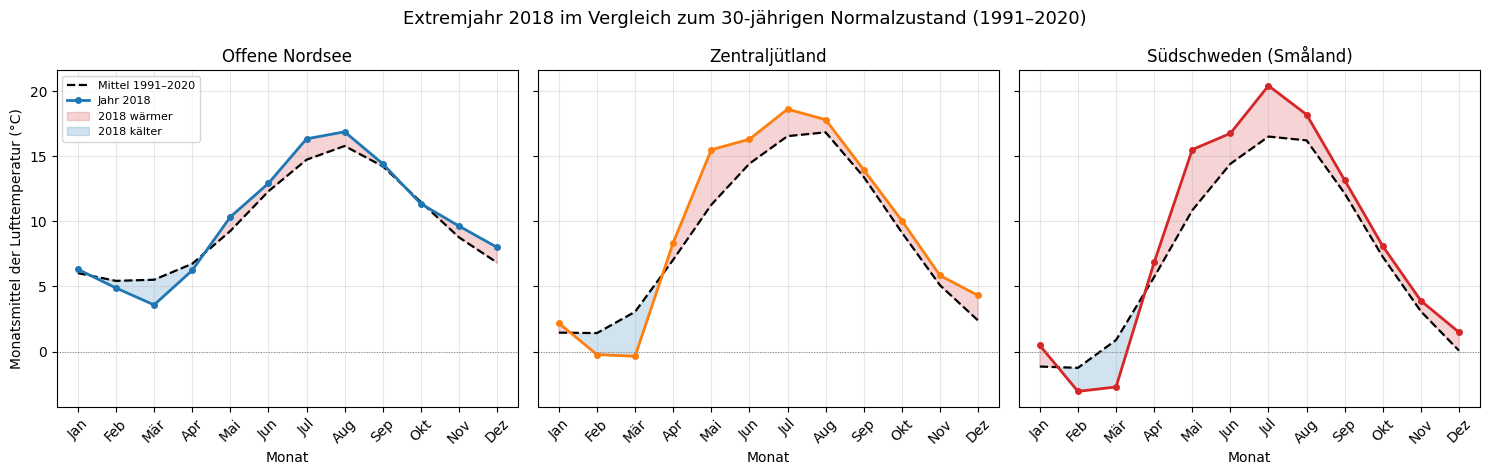

In [11]:
# Direktvergleich: Monatsmittel 2018 vs. 30-jähriger Normalzustand (1991-2020)
fokus_orte = [
    'Offene Nordsee',
    'Binnenland Dänemark (Zentraljütland)',
    'Binnenland Südschweden (Småland)',
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

for ax, name in zip(axes, fokus_orte):
    info = orte[name]
    klima_vals = punkte_klima[name].values
    monat_2018 = punkte_jahr[name].resample(time='1MS').mean()
    vals_2018 = monat_2018.values

    ax.plot(monate, klima_vals, color='black', linestyle='--', linewidth=1.6, label='Mittel 1991–2020')
    ax.plot(monate, vals_2018, color=info['color'], linestyle='-', marker='o', markersize=4, linewidth=2.0, label=f'Jahr {einzeljahr}')

    ax.fill_between(
        monate,
        klima_vals,
        vals_2018,
        where=vals_2018 >= klima_vals,
        interpolate=True,
        color='#d62728',
        alpha=0.2,
        label='2018 wärmer',
    )
    ax.fill_between(
        monate,
        klima_vals,
        vals_2018,
        where=vals_2018 < klima_vals,
        interpolate=True,
        color='#1f77b4',
        alpha=0.2,
        label='2018 kälter',
    )

    ax.axhline(0, color='grey', linewidth=0.7, linestyle=':')
    ax.set_xticks(monate)
    ax.set_xticklabels(monatsnamen, rotation=45)
    ax.set_title(info['kurz'])
    ax.set_xlabel('Monat')
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Monatsmittel der Lufttemperatur (°C)')
axes[0].legend(loc='upper left', fontsize=8)
fig.suptitle(f'Extremjahr {einzeljahr} im Vergleich zum 30-jährigen Normalzustand (1991–2020)', fontsize=13)
plt.tight_layout()
plt.show()

## 6. Wärmespeicher Nordsee: Heiz-/Kühlkurve und Hysterese (Poster-Abb. 4)

Neben der Dämpfung der Jahresamplitude bewirkt die hohe Wärmekapazität der Nordsee eine **zeitliche Verzögerung (*Thermal Lag*)**:
- Im **Frühling/Sommer (ca. April–August)** erwärmt sich das Land schneller – die Nordsee wirkt relativ zum Binnenland als **Kühlschrank** (`T_Land − T_Nordsee > 0`).
- Im **Herbst/Winter (ca. September–Februar)** gibt das Meer seine gespeicherte Sommerwärme nur langsam ab – die Nordsee wirkt als **Heizung** (`T_Land − T_Nordsee < 0`).

Trägt man die monatliche Meerestemperatur gegen die Landtemperatur auf, bildet der Jahreszyklus keine Gerade, sondern eine offene **Hysterese-Schleife**: Bei gleicher Landtemperatur ist die Nordsee im Oktober deutlich wärmer als im April.

In [12]:
# Flächengewichtete Zeitreihen und Monatsmittel für Nordsee (Meer) vs. Dänemark (Land)
t2m_nordsee_reg = t2m.sel(**nordsee_box).where(~landmaske.sel(**nordsee_box))
t2m_dk_reg = t2m.sel(**daenemark_box).where(landmaske.sel(**daenemark_box))

nordsee_zeitreihe = t2m_nordsee_reg.weighted(np.cos(np.deg2rad(t2m_nordsee_reg.lat))).mean(['lat', 'lon'])
daenemark_zeitreihe = t2m_dk_reg.weighted(np.cos(np.deg2rad(t2m_dk_reg.lat))).mean(['lat', 'lon'])

nordsee_monat = nordsee_zeitreihe.groupby('time.month').mean()
daenemark_monat = daenemark_zeitreihe.groupby('time.month').mean()

diff_reg = daenemark_monat - nordsee_monat
diff_dk = punkte_klima['Binnenland Dänemark (Zentraljütland)'] - punkte_klima['Offene Nordsee']
diff_se = punkte_klima['Binnenland Südschweden (Småland)'] - punkte_klima['Offene Nordsee']

print('Kältester und wärmster Monat im 30-Jahres-Mittel (1991–2020):')
alle_klima = [(orte[n]['kurz'], punkte_klima[n]) for n in orte]
alle_klima.append(('Fläche: Nordsee (Meer)', nordsee_monat))
alle_klima.append(('Fläche: Dänemark (Land)', daenemark_monat))

for label, kl in alle_klima:
    m_kalt = int(kl.idxmin('month'))
    m_warm = int(kl.idxmax('month'))
    v_kalt = float(kl.min('month'))
    v_warm = float(kl.max('month'))
    print(f'  {label:24s} | kältester: {monatsnamen[m_kalt - 1]} ({v_kalt:5.2f} °C) | wärmster: {monatsnamen[m_warm - 1]} ({v_warm:5.2f} °C)')

Kältester und wärmster Monat im 30-Jahres-Mittel (1991–2020):
  Offene Nordsee           | kältester: Feb ( 5.43 °C) | wärmster: Aug (15.78 °C)
  Westküste DK             | kältester: Feb ( 2.71 °C) | wärmster: Aug (17.02 °C)
  Zentraljütland           | kältester: Feb ( 1.42 °C) | wärmster: Aug (16.83 °C)
  Südschweden (Småland)    | kältester: Feb (-1.25 °C) | wärmster: Jul (16.50 °C)
  Fläche: Nordsee (Meer)   | kältester: Feb ( 5.09 °C) | wärmster: Aug (16.12 °C)
  Fläche: Dänemark (Land)  | kältester: Feb ( 1.58 °C) | wärmster: Aug (17.35 °C)


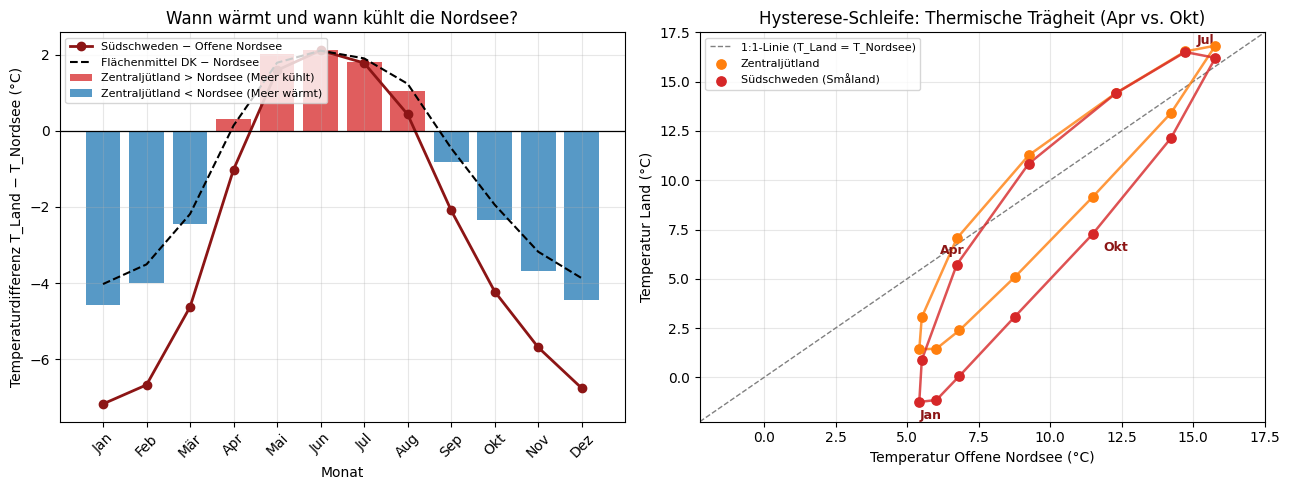

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Links: Heiz-/Kühlkurve
dk_diff_vals = diff_dk.values
axes[0].bar(
    monate,
    np.where(dk_diff_vals >= 0, dk_diff_vals, 0),
    color='#d62728',
    alpha=0.75,
    label='Zentraljütland > Nordsee (Meer kühlt)',
)
axes[0].bar(
    monate,
    np.where(dk_diff_vals < 0, dk_diff_vals, 0),
    color='#1f77b4',
    alpha=0.75,
    label='Zentraljütland < Nordsee (Meer wärmt)',
)
axes[0].plot(
    monate,
    diff_se.values,
    color='#8c1515',
    marker='o',
    linewidth=2,
    label='Südschweden − Offene Nordsee',
)
axes[0].plot(
    monate,
    diff_reg.values,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Flächenmittel DK − Nordsee',
)
axes[0].axhline(0, color='black', linewidth=0.9)
axes[0].set_xticks(monate)
axes[0].set_xticklabels(monatsnamen, rotation=45)
axes[0].set_xlabel('Monat')
axes[0].set_ylabel('Temperaturdifferenz T_Land − T_Nordsee (°C)')
axes[0].set_title('Wann wärmt und wann kühlt die Nordsee?')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper left', fontsize=8)

# Rechts: Hysterese-Streudiagramm (Thermische Trägheit)
t_ns = punkte_klima['Offene Nordsee'].values
t_dk = punkte_klima['Binnenland Dänemark (Zentraljütland)'].values
t_se = punkte_klima['Binnenland Südschweden (Småland)'].values

t_ns_loop = np.append(t_ns, t_ns[0])
t_dk_loop = np.append(t_dk, t_dk[0])
t_se_loop = np.append(t_se, t_se[0])

min_diag = min(float(t_ns.min()), float(t_se.min())) - 1.0
max_diag = max(float(t_ns.max()), float(t_se.max())) + 1.0
axes[1].plot([min_diag, max_diag], [min_diag, max_diag], color='grey', linestyle='--', linewidth=1, label='1:1-Linie (T_Land = T_Nordsee)')

col_dk = orte['Binnenland Dänemark (Zentraljütland)']['color']
col_se = orte['Binnenland Südschweden (Småland)']['color']

axes[1].plot(t_ns_loop, t_dk_loop, color=col_dk, linewidth=1.8, alpha=0.8)
axes[1].scatter(t_ns, t_dk, color=col_dk, s=45, zorder=4, label='Zentraljütland')

axes[1].plot(t_ns_loop, t_se_loop, color=col_se, linewidth=1.8, alpha=0.8)
axes[1].scatter(t_ns, t_se, color=col_se, s=45, zorder=4, label='Südschweden (Småland)')

monat_offsets = {
    0: (-12, -14),
    3: (-12, 8),
    6: (8, 6),
    9: (8, -12),
}
for idx, (dx, dy) in monat_offsets.items():
    axes[1].annotate(
        monatsnamen[idx],
        xy=(t_ns[idx], t_se[idx]),
        xytext=(dx, dy),
        textcoords='offset points',
        fontsize=9,
        fontweight='bold',
        color='#8c1515',
    )

axes[1].set_xlim(min_diag, max_diag)
axes[1].set_ylim(min_diag, max_diag)
axes[1].set_xlabel('Temperatur Offene Nordsee (°C)')
axes[1].set_ylabel('Temperatur Land (°C)')
axes[1].set_title('Hysterese-Schleife: Thermische Trägheit (Apr vs. Okt)')
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

## 7. Spanne zwischen Höchst- und Tiefsttemperatur (`T_max − T_min`) (Poster-Abb. 5)

Neben dem Jahresverlauf zeigt auch die **kurzfristige Spanne zwischen Höchst- und Tiefsttemperatur** (`max_air_temperature_2m - min_air_temperature_2m` pro 8-Tage-Zeitschritt) den dämpfenden Einfluss des Wassers. Über dem Meer ist diese Spanne ganzjährig gering; über Land steigt sie besonders im Frühjahr und Sommer stark an.

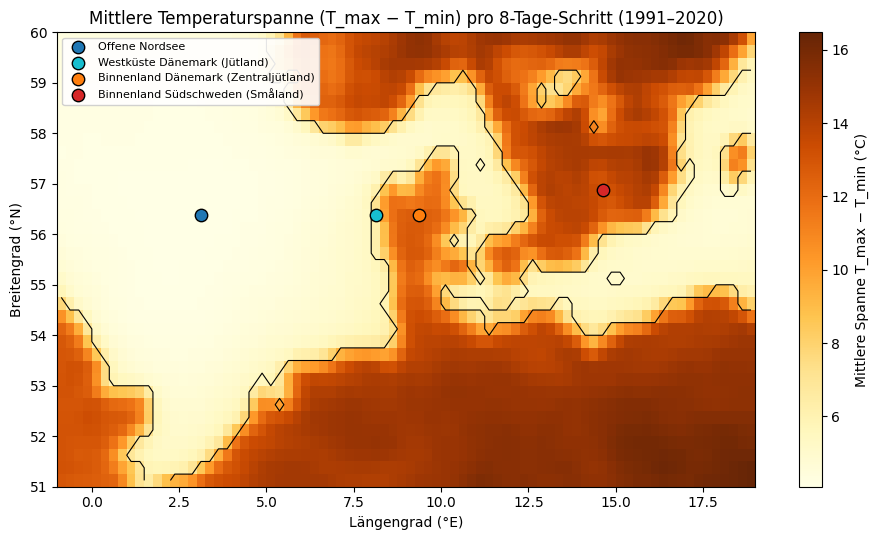

In [14]:
spanne = t_max - t_min
spanne_mittel = spanne.mean('time')
spanne_monat = spanne.groupby('time.month').mean()

fig, ax = plt.subplots(figsize=(9.5, 5.5))
spanne_mittel.plot(ax=ax, cmap='YlOrBr', cbar_kwargs={'label': 'Mittlere Spanne T_max − T_min (°C)'})
zeichne_kueste(ax)
for name, info in orte.items():
    ax.scatter(info['lon'], info['lat'], color=info['color'], edgecolor='black', s=80, zorder=5, label=name)

ax.set_title('Mittlere Temperaturspanne (T_max − T_min) pro 8-Tage-Schritt (1991–2020)')
ax.set_xlabel('Längengrad (°E)')
ax.set_ylabel('Breitengrad (°N)')
ax.legend(loc='upper left', fontsize=8, framealpha=0.9)
plt.tight_layout()
plt.show()

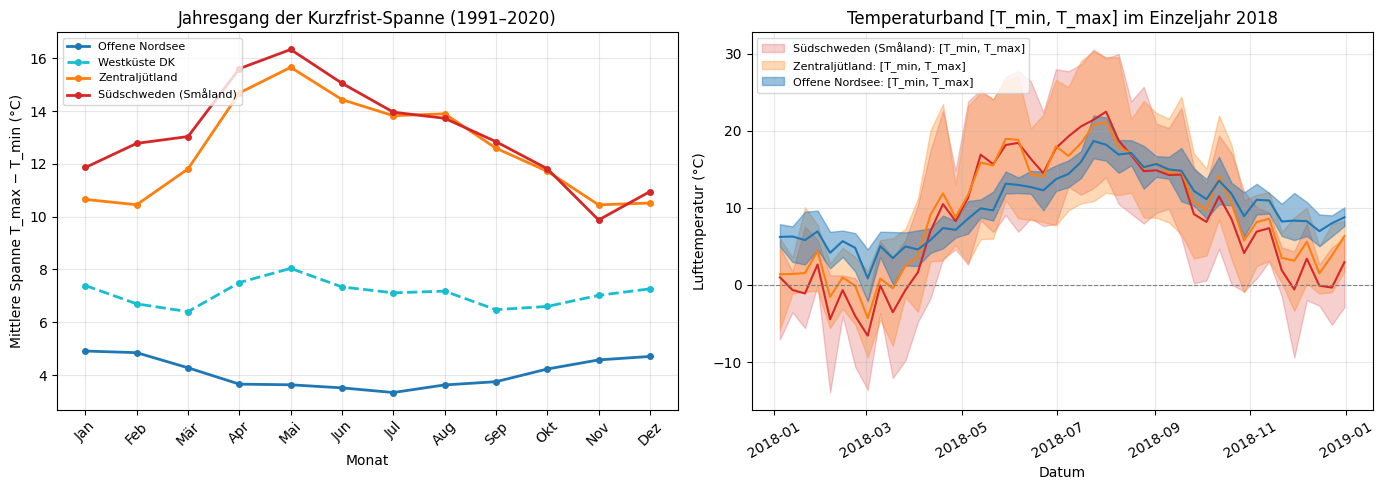

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Links: Jahresgang der mittleren Spanne T_max - T_min
for name, info in orte.items():
    s_mon = spanne_monat.sel(lat=info['lat'], lon=info['lon'], method='nearest')
    axes[0].plot(
        monate,
        s_mon.values,
        color=info['color'],
        linestyle=info['ls'],
        marker='o',
        markersize=4,
        linewidth=2,
        label=info['kurz'],
    )

axes[0].set_xticks(monate)
axes[0].set_xticklabels(monatsnamen, rotation=45)
axes[0].set_xlabel('Monat')
axes[0].set_ylabel('Mittlere Spanne T_max − T_min (°C)')
axes[0].set_title('Jahresgang der Kurzfrist-Spanne (1991–2020)')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper left', fontsize=8)

# Rechts: Temperaturband [T_min, T_max] im Einzeljahr 2018 (breitestes Band zuerst)
band_orte = [
    ('Binnenland Südschweden (Småland)', 0.22),
    ('Binnenland Dänemark (Zentraljütland)', 0.30),
    ('Offene Nordsee', 0.45),
]
for name, alpha_val in band_orte:
    info = orte[name]
    kurz_name = info['kurz']
    da_min = punkte_tmin_jahr[name]
    da_max = punkte_tmax_jahr[name]
    da_mean = punkte_jahr[name]
    axes[1].fill_between(
        da_min.time.values,
        da_min.values,
        da_max.values,
        color=info['color'],
        alpha=alpha_val,
        label=f'{kurz_name}: [T_min, T_max]',
    )
    axes[1].plot(da_mean.time.values, da_mean.values, color=info['color'], linewidth=1.5)

axes[1].axhline(0, color='grey', linewidth=0.8, linestyle='--')
axes[1].set_xlabel('Datum')
axes[1].set_ylabel('Lufttemperatur (°C)')
axes[1].set_title(f'Temperaturband [T_min, T_max] im Einzeljahr {einzeljahr}')
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

## 8. Methoden-Check und Limitationen: Küsten-Mischpixel bei 0,25°-Auflösung

In der Aufgabenstellung (Folie 3) wird ausdrücklich darauf hingewiesen, dass Rasterzellen direkt an der Küste aufgrund der groben 0,25°-Auflösung sowohl Land- als auch Wasseranteile enthalten können. Um diesen Übergang quantitativ zu prüfen, betrachten wir sieben aufeinanderfolgende Gitterzellen quer über die dänische Westküste bei `56,375° N` – vom reinen Nordseepixel (`7,375° E`) bis ins zentrale Jütland (`9,375° E`).

Küsten-Querschnitt bei 56.375° N (Westküste Jütland):
Längengrad |  Maske |  Amplitude |  Spanne Tmax-Tmin
----------------------------------------------------
    7.375° | Wasser |    12.98 °C |            4.93 °C
    7.625° | Wasser |    13.32 °C |            5.07 °C
    7.875° | Wasser |    13.70 °C |            5.33 °C
    8.125° |   Land |    14.30 °C |            7.09 °C
    8.375° |   Land |    14.89 °C |           10.04 °C
    8.625° |   Land |    15.13 °C |           11.86 °C
    9.375° |   Land |    15.41 °C |           12.57 °C


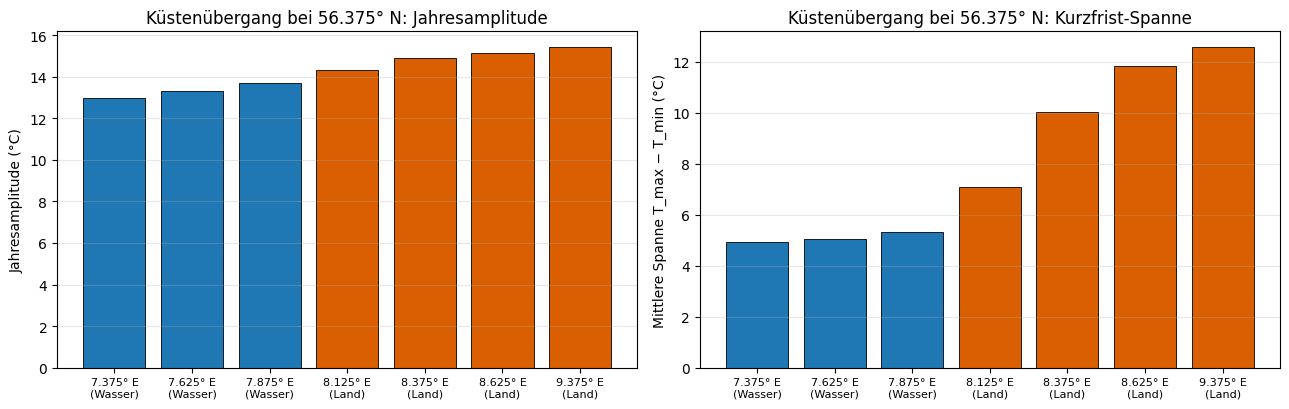

In [16]:
lons_check = [7.375, 7.625, 7.875, 8.125, 8.375, 8.625, 9.375]
check_records = []

h_lon = 'Längengrad'
h_mask = 'Maske'
h_amp = 'Amplitude'
h_sp = 'Spanne Tmax-Tmin'

print(f'Küsten-Querschnitt bei {transekt_lat:.3f}° N (Westküste Jütland):')
print(f'{h_lon:>10s} | {h_mask:>6s} | {h_amp:>10s} | {h_sp:>17s}')
print('-' * 52)

for lo in lons_check:
    ist_land = bool(landmaske.sel(lat=transekt_lat, lon=lo, method='nearest'))
    amp_val = float(amplitude.sel(lat=transekt_lat, lon=lo, method='nearest'))
    sp_val = float(spanne_mittel.sel(lat=transekt_lat, lon=lo, method='nearest'))
    status = 'Land' if ist_land else 'Wasser'
    check_records.append((lo, status, amp_val, sp_val))
    print(f'{lo:9.3f}° | {status:>6s} | {amp_val:8.2f} °C | {sp_val:15.2f} °C')

x_pos = np.arange(len(check_records))
x_labels = [f'{rec[0]:.3f}° E\n({rec[1]})' for rec in check_records]
amp_vals = [rec[2] for rec in check_records]
sp_vals = [rec[3] for rec in check_records]
bar_colors = ['#1f77b4' if rec[1] == 'Wasser' else '#d95f02' for rec in check_records]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(x_pos, amp_vals, color=bar_colors, edgecolor='black', linewidth=0.6)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(x_labels, fontsize=8)
axes[0].set_ylabel('Jahresamplitude (°C)')
axes[0].set_title(f'Küstenübergang bei {transekt_lat:.3f}° N: Jahresamplitude')
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].bar(x_pos, sp_vals, color=bar_colors, edgecolor='black', linewidth=0.6)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(x_labels, fontsize=8)
axes[1].set_ylabel('Mittlere Spanne T_max − T_min (°C)')
axes[1].set_title(f'Küstenübergang bei {transekt_lat:.3f}° N: Kurzfrist-Spanne')
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Bewertung der methodischen Grenzen
1. **Grobe räumliche Auflösung (0,25° × 0,25°):** Bei ~56° N entspricht eine Rasterzelle rund 28 km (Nord–Süd) × 15,5 km (Ost–West). Küstennahe Zellen (wie bei `8,125° E`) mischen Land- und Wasserflächen und zeigen deshalb eine abgeschwächte Übergangsamplitude. Auch kleinere Fjorde und Inseln (z. B. Limfjord, Fünen, Seeland) werden im 0,25°-Raster stark geglättet.
2. **Begrenzte Binnenland-Tiefe in Dänemark:** Da Jütland und die dänischen Inseln von Nordsee, Kattegat und Ostsee umschlossen sind, liegt kein Ort in Dänemark weit im Landesinneren (~52 km max. Küstenferne). Erst die Einbeziehung des direkten Nachbarn **Südschweden (Småland)** auf nahezu gleicher Breite zeigt den vollen Anstieg hin zu kontinentaleren Verhältnissen.
3. **8-Tage-Mittelung (`8D`):** Einzelne extreme Hitzetage oder Kältenächte werden innerhalb eines 8-Tage-Schritts gemittelt. Dennoch bleiben sowohl der Kontrast in der Jahresamplitude als auch in der Spanne `T_max − T_min` zwischen Meer und Land eindeutig nachweisbar.
4. **Landmaske über Vegetationsdaten (`gross_primary_productivity`):** Die abgeleitete Maske trennt offenes Meer und Landflächen sauber, ordnet Mischzellen an der Küste jedoch binär entweder als Land oder als Wasser ein.

## 9. Kennzahlen-Zusammenfassung und Poster-Storyline (Roter Faden)

Die folgende Code-Zelle fasst alle zentralen Kennzahlen für die vier Vergleichsorte sowie die beiden flächengewichteten Gebiete **Nordsee (Meer)** und **Dänemark (Land)** in einer kompakten Übersichtstabelle zusammen.

In [17]:
spanne_ns_reg = spanne_mittel.sel(**nordsee_box).where(~landmaske.sel(**nordsee_box))
spanne_dk_reg = spanne_mittel.sel(**daenemark_box).where(landmaske.sel(**daenemark_box))
spanne_ns_wert = float(spanne_ns_reg.weighted(np.cos(np.deg2rad(spanne_ns_reg.lat))).mean(['lat', 'lon']))
spanne_dk_wert = float(spanne_dk_reg.weighted(np.cos(np.deg2rad(spanne_dk_reg.lat))).mean(['lat', 'lon']))

eintraege = []
for name, info in orte.items():
    sp_ort = float(spanne_mittel.sel(lat=info['lat'], lon=info['lon'], method='nearest'))
    eintraege.append((info['kurz'], punkte_t2m[name], punkte_klima[name], sp_ort))

eintraege.append(('Fläche: Nordsee (Meer)', nordsee_zeitreihe, nordsee_monat, spanne_ns_wert))
eintraege.append(('Fläche: Dänemark (Land)', daenemark_zeitreihe, daenemark_monat, spanne_dk_wert))

c1 = 'Standort / Region'
c2 = 'Mittel'
c3 = 'Kältester Mon.'
c4 = 'Wärmster Mon.'
c5 = 'Amplitude'
c6 = 'Spanne'
c7 = f'{einzeljahr} Min..Max'

print(f'Zusammenfassung der Temperaturkennzahlen (1991–2020 bzw. Einzeljahr {einzeljahr})')
print('=' * 102)
print(f'{c1:28s} | {c2:>7s} | {c3:>14s} | {c4:>14s} | {c5:>9s} | {c6:>7s} | {c7:>14s}')
print('-' * 102)

for label, zr, kl, sp_val in eintraege:
    jahresmittel = float(zr.mean('time'))
    kalt_mon_idx = int(kl.idxmin('month'))
    warm_mon_idx = int(kl.idxmax('month'))
    kalt_wert = float(kl.min('month'))
    warm_wert = float(kl.max('month'))
    amp = warm_wert - kalt_wert

    zr_jahr = zr.sel(time=einzeljahr)
    jahr_min = float(zr_jahr.min('time'))
    jahr_max = float(zr_jahr.max('time'))

    kalt_str = f'{kalt_wert:5.1f}° ({monatsnamen[kalt_mon_idx - 1]})'
    warm_str = f'{warm_wert:5.1f}° ({monatsnamen[warm_mon_idx - 1]})'
    minmax_str = f'{jahr_min:5.1f}..{jahr_max:5.1f}°'

    print(f'{label:28s} | {jahresmittel:6.2f}° | {kalt_str:>14s} | {warm_str:>14s} | {amp:8.2f}° | {sp_val:6.2f}° | {minmax_str:>14s}')

Zusammenfassung der Temperaturkennzahlen (1991–2020 bzw. Einzeljahr 2018)
Standort / Region            |  Mittel | Kältester Mon. |  Wärmster Mon. | Amplitude |  Spanne |  2018 Min..Max
------------------------------------------------------------------------------------------------------
Offene Nordsee               |   9.73° |     5.4° (Feb) |    15.8° (Aug) |    10.35° |   4.08° |    0.8.. 18.7°
Westküste DK                 |   9.26° |     2.7° (Feb) |    17.0° (Aug) |    14.30° |   7.09° |   -2.4.. 19.9°
Zentraljütland               |   8.48° |     1.4° (Feb) |    16.8° (Aug) |    15.41° |  12.57° |   -4.3.. 21.1°
Südschweden (Småland)        |   7.04° |    -1.2° (Feb) |    16.5° (Jul) |    17.75° |  13.14° |   -6.6.. 22.5°
Fläche: Nordsee (Meer)       |   9.86° |     5.1° (Feb) |    16.1° (Aug) |    11.02° |   4.31° |    0.3.. 18.6°
Fläche: Dänemark (Land)      |   8.85° |     1.6° (Feb) |    17.4° (Aug) |    15.77° |  10.26° |   -3.7.. 21.7°


### Poster-Leitfaden und Zuordnung zum Bewertungsschema

Für das spätere wissenschaftliche Poster (Aufbau nach Folie 7–9 der Aufgabenstellung) greifen die Ergebnisse dieses Notebooks nahtlos als roter Faden ineinander:

1. **Einleitung (These & Fragestellung):**  
   Gleiche geografische Breite (~56,4°–56,9° N), gleiche Sonneneinstrahlung – warum schwankt die Temperatur trotzdem über dem Land deutlich stärker als über dem Meer? (Physik: hohe Wärmekapazität & Durchmischung des Meerwassers).
2. **Material & Methoden:**  
   ESDC v3.0.2 (ERA5-Lufttemperatur `air_temperature_2m`, `max_air_temperature_2m`, `min_air_temperature_2m`; 0,25° × 0,25°; 8-Tage-Auflösung; Normalperiode 1991–2020 vs. Extremjahr 2018); Landmaske aus `gross_primary_productivity`; flächengewichtete Mittelwerte (`cos(lat)`).
3. **Ergebnisse (5 Kern-Abbildungen):**  
   - **Abb. 1 (Abschnitt 3):** Karte der Jahresamplitude + Differenzkarte `SON − MAM` → zeigt räumlich sowohl die Dämpfung über Nord- und Ostsee als auch die herbstliche Wärmespeicherung.
   - **Abb. 2 (Abschnitt 4):** West–Ost-Profil entlang 56,375° N → zeigt den „Doppel-Peak“ (Nordsee → Jütland → Kattegat → Südschweden → Ostsee) bei Amplitude sowie Sommer-/Wintertemperatur.
   - **Abb. 3 (Abschnitt 5):** Vergleich des mittleren Jahresgangs (1991–2020) mit dem Extremjahr 2018 an den Vergleichsorten.
   - **Abb. 4 (Abschnitt 6):** Heiz-/Kühlkurve (`T_Land − T_Nordsee`) und Hysterese-Schleife (April vs. Oktober) → belegt die zeitliche Phasenverschiebung.
   - **Abb. 5 (Abschnitt 7):** Kurzfrist-Spanne `T_max − T_min` (Karte + Bandbreite 2018).
4. **Diskussion & Limitationen (Abschnitt 8):**  
   Auswertung der Küsten-Mischpixel bei 0,25° (Abb. aus Abschnitt 8), geringe Binnenland-Tiefe Dänemarks als Grund für die Einbeziehung Südschwedens, Effekt der 8-Tage-Mittelung.
5. **Fazit:**  
   Die Nordsee dämpft Dänemarks Jahresamplitude und Temperaturspannen spürbar und verschiebt das Temperaturmaximum/ -minimum zeitlich nach hinten; erst im Binnenland Südschwedens tritt auf gleicher Breite ein deutlich kontinentaleres Klima hervor.
6. **Wissenschaftliche Belege / Literatur (für die Quellenbox auf dem Poster):**  
   - Hersbach, H. et al. (2020): *The ERA5 global reanalysis*. Quarterly Journal of the Royal Meteorological Society, 146(730), 1999–2049.  
   - Mahecha, M. D. et al. (2020): *Earth system data cubes unravel global multivariate dynamics*. Earth System Dynamics, 11(1), 201–234.  
   - Häckel, H. (2021): *Meteorologie* (Kapitel Wärmehaushalt & Land-See-Kontrast) sowie ergänzende Klimaberichte von DMI / DWD zum Vergleichsjahr 2018.